# 02 · A/B test: did the e-mails work, and which one is better?

Notebook 01 showed the experiment is sound: the three groups are the same kinds of customers. This notebook
measures **what each e-mail did** in the two weeks after it was sent.

**Comparisons** (each e-mail against doing nothing, and the two e-mails against each other):
1. Men's e-mail vs control
2. Women's e-mail vs control
3. Men's e-mail vs women's e-mail

**Metrics.** These follow the customer journey: e-mail → website visit → purchase → money spent.

| Metric | Role | Why |
|---|---|---|
| Spend per customer (\$) | **Primary** | Revenue is what the business ultimately cares about. It combines *how many* buy and *how much* they spend. |
| Visit rate | Secondary | Did the e-mail get people's attention? |
| Conversion rate | Secondary | Did the attention turn into purchases? |

**Rules fixed before looking at the results.** Choosing methods after seeing the data invites picking whichever
version looks best, so we fix them up front:
- 95% confidence intervals and a significance level of **α = 0.05** (two-sided: an e-mail could also *hurt*).
- Each metric has 3 comparisons, so we adjust the p-values with the **Holm method** (explained in section 4).
- We judge results on **effect size and business value**, not only on whether p < 0.05.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_confint

from src.style import ARM_ORDER, ARM_LABELS, ARM_COLORS, set_style
from src.data import load_clean
from src.stats import two_proportion_test, mean_difference_test, bootstrap_means, holm

ALPHA = 0.05
SEED = 42
N_BOOT = 10_000
rng = np.random.default_rng(SEED)

set_style()
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.html.use_mathjax", False)  # show "$" in tables literally, not as math
FIG_DIR = ROOT / "figures"

df = load_clean()
print(f"{len(df):,} customers loaded")

64,000 customers loaded


## 1. The headline numbers

First, the plain averages per group. They answer "what happened?". The rest of the notebook answers "how sure
can we be, and is it worth it?".

In [2]:
by_arm = (df.groupby("segment", observed=True)
            .agg(customers=("visit", "size"), visits=("visit", "sum"), buyers=("conversion", "sum"),
                 revenue=("spend", "sum"), visit_rate=("visit", "mean"),
                 conversion_rate=("conversion", "mean"), spend_per_customer=("spend", "mean"))
            .reindex(ARM_ORDER))
by_arm["avg_order_value"] = by_arm.revenue / by_arm.buyers
by_arm.rename(index=ARM_LABELS)

,customers,visits,buyers,revenue,visit_rate,conversion_rate,spend_per_customer,avg_order_value
segment,,,,,,,,
Control (no e-mail),21306,2262,122,"13,908.3300",0.1062,0.0057,0.6528,114.0027
Men's e-mail,21307,3894,267,"30,311.6900",0.1828,0.0125,1.4226,113.5269
Women's e-mail,21387,3238,189,"23,038.1100",0.1514,0.0088,1.0772,121.8948


## 2. Visits and purchases: yes/no outcomes

Each customer either visited (1) or didn't (0), and either bought (1) or didn't (0). To compare two groups'
rates we use:

- **Two-proportion z-test → p-value.** It asks: *if the e-mail had no effect at all, how likely is a gap this
  large just from the luck of who landed in which group?* A small p-value means "very unlikely by luck alone".
  This test is reliable here because each group has thousands of visits and over a hundred purchases.
- **Newcombe confidence interval → range for the difference.** It gives the range of percentage-point
  differences that are consistent with the data. We use Newcombe rather than the textbook formula because the
  textbook version is less accurate for small rates like a ~1% conversion rate.
- **Relative lift.** "+0.7 percentage points" is hard to judge on its own; "+120% more buyers" is easier. We
  report both, each with its own interval.

In [3]:
COMPARISONS = [("Mens E-Mail", "No E-Mail"), ("Womens E-Mail", "No E-Mail"), ("Mens E-Mail", "Womens E-Mail")]
COMP_LABELS = {c: f"{ARM_LABELS[c[0]]} vs {ARM_LABELS[c[1]].lower()}" for c in COMPARISONS}
COMP_COLORS = {COMPARISONS[0]: ARM_COLORS["Mens E-Mail"], COMPARISONS[1]: ARM_COLORS["Womens E-Mail"],
               COMPARISONS[2]: "#4c4c4c"}

def arm(name, col):
    return df.loc[df.segment == name, col].to_numpy()

results = []
for metric in ["visit", "conversion"]:
    for a, b in COMPARISONS:
        results.append({"metric": metric, "comparison": (a, b),
                        **two_proportion_test(arm(a, metric), arm(b, metric), alpha=ALPHA)})
(pd.DataFrame(results)
   .assign(comparison=lambda d: d.comparison.map(COMP_LABELS))
   .set_index(["metric", "comparison"])[["value_a", "value_b", "diff", "diff_ci_low", "diff_ci_high", "p_value"]])

value_a  value_b   diff  \
metric     comparison                                                       
visit      Men's e-mail vs control (no e-mail)     0.1828   0.1062 0.0766   
           Women's e-mail vs control (no e-mail)   0.1514   0.1062 0.0452   
           Men's e-mail vs women's e-mail          0.1828   0.1514 0.0314   
conversion Men's e-mail vs control (no e-mail)     0.0125   0.0057 0.0068   
           Women's e-mail vs control (no e-mail)   0.0088   0.0057 0.0031   
           Men's e-mail vs women's e-mail          0.0125   0.0088 0.0037   

                                                  diff_ci_low  diff_ci_high  \
metric     comparison                                                         
visit      Men's e-mail vs control (no e-mail)         0.0700        0.0832   
           Women's e-mail vs control (no e-mail)       0.0389        0.0516   
           Men's e-mail vs women's e-mail              0.0243        0.0384   
conversion Men's e-mail vs control (no e-mail)         0.0050        0.0086   
           Women's e-mail vs control (no e-mail)       0.0015        0.0047   
           Men's e-mail vs women's e-mail              0.0017        0.0057   

                                                  p_value  
metric     comparison                                      
visit      Men's e-mail vs control (no e-mail)     0.0000  
           Women's e-mail vs control (no e-mail)   0.0000  
           Men's e-mail vs women's e-mail          0.0000  
conversion Men's e-mail vs control (no e-mail)     0.0000  
           Women's e-mail vs control (no e-mail)   0.0002  
           Men's e-mail vs women's e-mail          0.0002

## 3. Spend per customer: a skewed outcome

Spend is harder to analyse: 99% of customers spend \$0, and a handful spend up to \$499 (see notebook 01). Two
methods complement each other here:

- **Bootstrap → confidence interval.** We simulate re-running the experiment by drawing customers *with
  replacement* from each group, 10,000 times, and recomputing the difference in average spend each time. The middle
  95% of those 10,000 differences is our confidence interval. It makes **no assumption** about the shape of the
  spend distribution, which is why it suits zero-heavy, skewed data.
- **Welch's t-test → p-value, and a cross-check on the interval.** A plain t-test assumes both groups have the same
  spread; Welch's version doesn't, which matters because e-mailed groups have more buyers and therefore more
  spread. The t-test also assumes the *average* (not each customer's spend) is roughly bell-shaped. With 21,000+
  customers per group that holds even for skewed data (the central limit theorem). If the Welch and bootstrap
  intervals agree, we can trust both.

In [4]:
for a, b in COMPARISONS:
    results.append({"metric": "spend", "comparison": (a, b),
                    **mean_difference_test(arm(a, "spend"), arm(b, "spend"), rng, n_boot=N_BOOT, alpha=ALPHA)})

spend_check = pd.DataFrame([
    {"comparison": COMP_LABELS[r["comparison"]], "difference ($)": r["diff"],
     "bootstrap CI": f"[{r['diff_ci_low']:.3f}, {r['diff_ci_high']:.3f}]",
     "Welch CI": f"[{r['welch_ci_low']:.3f}, {r['welch_ci_high']:.3f}]", "Welch p-value": r["p_value"]}
    for r in results if r["metric"] == "spend"]).set_index("comparison")
spend_check

,difference ($),bootstrap CI,Welch CI,Welch p-value
comparison,,,,
Men's e-mail vs control (no e-mail),0.7698,"[0.487, 1.059]","[0.485, 1.055]",0.0000
Women's e-mail vs control (no e-mail),0.4244,"[0.173, 0.686]","[0.169, 0.680]",0.0011
Men's e-mail vs women's e-mail,0.3454,"[0.033, 0.654]","[0.033, 0.658]",0.0305


## 4. All results, corrected for multiple comparisons

**Why correct?** Each test at α = 0.05 has a 5% chance of a false alarm. With three comparisons per metric, the
chance that *at least one* is a false alarm rises to about 14%. The **Holm method** restores the 5% overall
error rate. It works like this:
1. Sort the three p-values from smallest to largest.
2. Hold the smallest to a stricter bar (0.05 / 3), the next to 0.05 / 2, and the last to 0.05.
3. Stop at the first one that fails.

Holm is always at least as powerful as the better-known Bonferroni correction (which uses 0.05 / 3 for all three),
so it costs us less. We apply it separately to each metric (a "family" of 3 comparisons).

How to read the table: *Difference* is the effect in percentage points (pp) or dollars, with its 95% interval in
brackets. If the interval excludes 0, the effect is clearly real in that direction.

In [5]:
res = pd.DataFrame(results)
res["p_holm"], res["significant"] = np.nan, False
for metric, idx in res.groupby("metric").groups.items():
    res.loc[idx, "p_holm"], res.loc[idx, "significant"] = holm(res.loc[idx, "p_value"], alpha=ALPHA)

METRIC_NAMES = {"visit": "Visit rate", "conversion": "Conversion rate", "spend": "Spend per customer"}

def fmt_level(metric, v):
    return f"${v:.2f}" if metric == "spend" else f"{v:.2%}"

def fmt_diff(metric, v):
    return f"{'+' if v >= 0 else '−'}${abs(v):.3f}" if metric == "spend" else f"{v * 100:+.2f} pp"

def fmt_p(p):
    return "< 0.0001" if p < 1e-4 else f"{p:.4f}"

pretty = pd.DataFrame({
    "Metric": res.metric.map(METRIC_NAMES),
    "Comparison": res.comparison.map(COMP_LABELS),
    "A": [fmt_level(m, v) for m, v in zip(res.metric, res.value_a)],
    "B": [fmt_level(m, v) for m, v in zip(res.metric, res.value_b)],
    "Difference A − B [95% CI]": [f"{fmt_diff(m, d)} [{fmt_diff(m, lo)}, {fmt_diff(m, hi)}]"
                                  for m, d, lo, hi in zip(res.metric, res["diff"], res.diff_ci_low, res.diff_ci_high)],
    "Relative lift [95% CI]": [f"{r:+.0%} [{lo:+.0%}, {hi:+.0%}]"
                               for r, lo, hi in zip(res.rel_lift, res.rel_ci_low, res.rel_ci_high)],
    "p (Holm)": res.p_holm.map(fmt_p),
    "Significant": res.significant.map({True: "yes", False: "no"}),
})
metric_order = {"spend": 0, "visit": 1, "conversion": 2}
pretty = pretty.iloc[res.metric.map(metric_order).argsort(kind="stable")].reset_index(drop=True)
pretty

,Metric,Comparison,A,B,Difference A − B [95% CI],Relative lift [95% CI],p (Holm),Significant
0,Spend per customer,Men's e-mail vs control (no e-mail),$1.42,$0.65,"+$0.770 [+$0.487, +$1.059]","+118% [+64%, +196%]",< 0.0001,yes
1,Spend per customer,Women's e-mail vs control (no e-mail),$1.08,$0.65,"+$0.424 [+$0.173, +$0.686]","+65% [+23%, +126%]",0.0023,yes
2,Spend per customer,Men's e-mail vs women's e-mail,$1.42,$1.08,"+$0.345 [+$0.033, +$0.654]","+32% [+3%, +70%]",0.0305,yes
3,Visit rate,Men's e-mail vs control (no e-mail),18.28%,10.62%,"+7.66 pp [+7.00 pp, +8.32 pp]","+72% [+64%, +81%]",< 0.0001,yes
4,Visit rate,Women's e-mail vs control (no e-mail),15.14%,10.62%,"+4.52 pp [+3.89 pp, +5.16 pp]","+43% [+36%, +50%]",< 0.0001,yes
5,Visit rate,Men's e-mail vs women's e-mail,18.28%,15.14%,"+3.14 pp [+2.43 pp, +3.84 pp]","+21% [+16%, +26%]",< 0.0001,yes
6,Conversion rate,Men's e-mail vs control (no e-mail),1.25%,0.57%,"+0.68 pp [+0.50 pp, +0.86 pp]","+119% [+77%, +171%]",< 0.0001,yes
7,Conversion rate,Women's e-mail vs control (no e-mail),0.88%,0.57%,"+0.31 pp [+0.15 pp, +0.47 pp]","+54% [+23%, +94%]",0.0003,yes
8,Conversion rate,Men's e-mail vs women's e-mail,1.25%,0.88%,"+0.37 pp [+0.17 pp, +0.57 pp]","+42% [+18%, +71%]",0.0003,yes


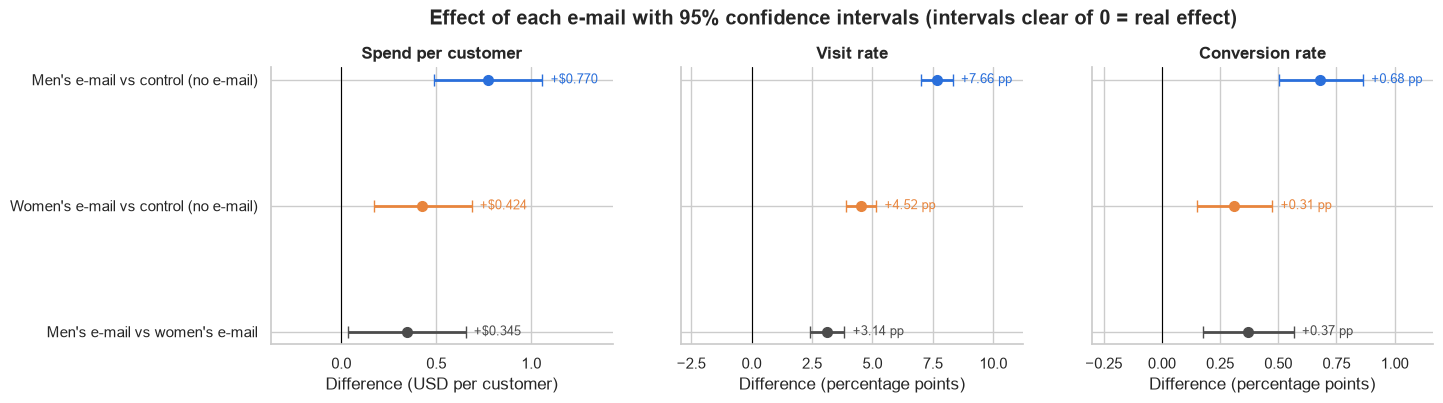

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, metric in zip(axes, ["spend", "visit", "conversion"]):
    sub = res[res.metric == metric].reset_index(drop=True)
    scale = 1 if metric == "spend" else 100
    for i, r in sub.iterrows():
        color = COMP_COLORS[r.comparison]
        ax.errorbar(r["diff"] * scale, i, xerr=[[(r["diff"] - r.diff_ci_low) * scale], [(r.diff_ci_high - r["diff"]) * scale]],
                    fmt="o", color=color, ecolor=color, capsize=4, lw=2, ms=7)
        ax.annotate(fmt_diff(metric, r["diff"]), (r.diff_ci_high * scale, i), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=9, color=color)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(METRIC_NAMES[metric])
    ax.set_xlabel("Difference (USD per customer)" if metric == "spend" else "Difference (percentage points)")
    ax.margins(x=0.35)
axes[0].set_yticks(range(len(COMPARISONS)), [COMP_LABELS[c] for c in COMPARISONS])
axes[0].invert_yaxis()
fig.suptitle("Effect of each e-mail with 95% confidence intervals (intervals clear of 0 = real effect)",
             fontweight="bold", y=1.04)
fig.savefig(FIG_DIR / "02_effects_forest.png")
plt.show()

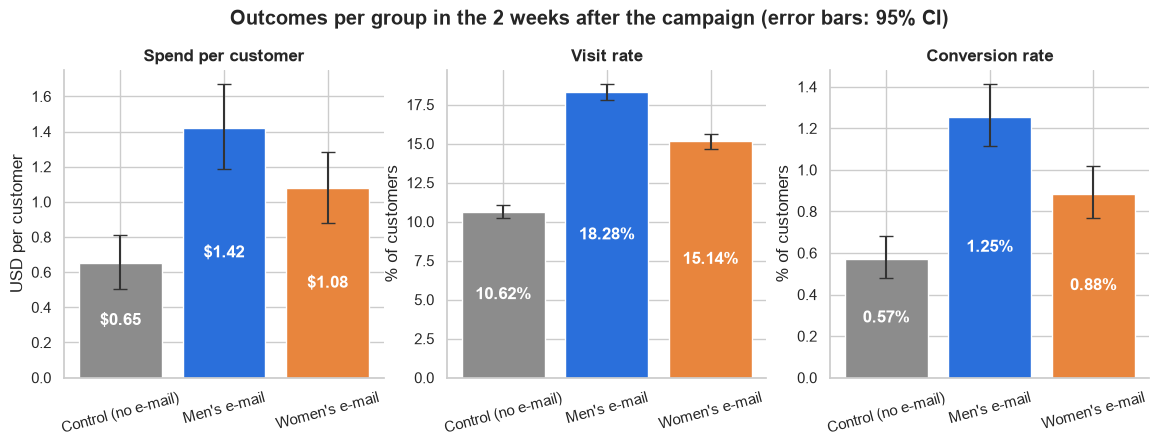

In [7]:
# The same story as levels per group, which is easier for non-technical readers
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
labels = [ARM_LABELS[a] for a in ARM_ORDER]
colors = [ARM_COLORS[a] for a in ARM_ORDER]
for ax, metric in zip(axes, ["spend", "visit", "conversion"]):
    if metric == "spend":
        means = by_arm.spend_per_customer.to_numpy()
        boots = [bootstrap_means(arm(a, "spend"), N_BOOT, rng) for a in ARM_ORDER]
        lo = means - [np.percentile(b, 2.5) for b in boots]
        hi = [np.percentile(b, 97.5) for b in boots] - means
        bar_text = [f"${m:.2f}" for m in means]
        ax.set_ylabel("USD per customer")
    else:
        x, n = by_arm[{"visit": "visits", "conversion": "buyers"}[metric]], by_arm.customers
        ci_lo, ci_hi = proportion_confint(x, n, alpha=ALPHA, method="wilson")
        means = (x / n).to_numpy() * 100
        lo, hi = means - ci_lo.to_numpy() * 100, ci_hi.to_numpy() * 100 - means
        bar_text = [f"{m:.2f}%" for m in means]
        ax.set_ylabel("% of customers")
    bars = ax.bar(labels, means, color=colors, yerr=[lo, hi], capsize=5, ecolor="#333333")
    ax.bar_label(bars, labels=bar_text, label_type="center", color="white", fontweight="bold")
    ax.set_title(METRIC_NAMES[metric])
    ax.tick_params(axis="x", labelrotation=15)
fig.suptitle("Outcomes per group in the 2 weeks after the campaign (error bars: 95% CI)", fontweight="bold", y=1.03)
fig.savefig(FIG_DIR / "02_outcomes_by_group.png")
plt.show()

## 5. Where does the extra spend come from?

Spend per customer can be split into two parts:

$$\text{spend per customer} = \text{conversion rate} \times \text{average order value (AOV)}$$

The table below shows which part each e-mail moved.

⚠️ **Caution on AOV.** Conversion and spend per customer compare *all* customers in each group, which is a fair,
randomized comparison. AOV only looks at *buyers*, and the e-mail changes who becomes a buyer. If the e-mail tempts
extra customers into small purchases, AOV can fall even though every customer who would have bought anyway spent
just as much. So we treat AOV differences as **descriptive clues**, not causal effects, and we do not test them.

In [8]:
orders = df[df.conversion == 1]
decomp = by_arm[["conversion_rate", "avg_order_value", "spend_per_customer"]].copy()
decomp["median_order_value"] = orders.groupby("segment", observed=True).spend.median().reindex(ARM_ORDER)
decomp["share_of_orders_under_$50"] = (orders.spend < 50).groupby(orders.segment, observed=True).mean().reindex(ARM_ORDER)
decomp.rename(index=ARM_LABELS)

,conversion_rate,avg_order_value,spend_per_customer,median_order_value,share_of_orders_under_$50
segment,,,,,
Control (no e-mail),0.0057,114.0027,0.6528,88.3650,0.3033
Men's e-mail,0.0125,113.5269,1.4226,66.9800,0.4045
Women's e-mail,0.0088,121.8948,1.0772,94.7100,0.3439


## 6. Sharpening the estimates: regression adjustment (CUPED-style)

Part of why customers' outcomes differ is unrelated to the e-mail: recent, high-spending, multichannel customers
buy more anyway. That background variation is *noise* that widens our confidence intervals. Because the variables
describing it (`recency`, `history`, `mens`, `womens`, `newbie`, `zip_code`, `channel`) were recorded **before**
the e-mail, the e-mail can't have affected them. That makes it safe to "subtract out" what they predict. This is
the idea behind **CUPED** and regression adjustment, which are standard at companies that run many experiments.

How we do it:
- **Linear regression** of each outcome on the treatment group, with and without the pre-treatment variables.
  For a 0/1 outcome this is a *linear probability model*: the treatment coefficient reads directly as a difference
  in percentage points, which is easy to explain.
- **Robust (HC1) standard errors.** Ordinary regression assumes every customer's outcome is equally noisy, which is
  false for 0/1 and zero-heavy outcomes. Robust standard errors drop that assumption.

What to expect: because of randomization, the *estimate* should barely change. If it moved a lot, that would point
to a problem. The *interval* should get somewhat narrower, by however much the covariates actually predict the
outcome.

In [9]:
COVARIATES = "recency + history + mens + womens + newbie + C(zip_code) + C(channel)"
rows = []
for metric in ["spend", "visit", "conversion"]:
    fits = {"unadjusted": smf.ols(f"{metric} ~ C(treatment)", data=df).fit(cov_type="HC1"),
            "adjusted": smf.ols(f"{metric} ~ C(treatment) + {COVARIATES}", data=df).fit(cov_type="HC1")}
    for t in ["mens", "womens"]:
        term = f"C(treatment)[T.{t}]"
        row = {"metric": METRIC_NAMES[metric], "comparison": f"{t} vs control"}
        for name, fit in fits.items():
            lo, hi = fit.conf_int(alpha=ALPHA).loc[term]
            row[f"{name}_estimate"] = fit.params[term]
            row[f"{name}_ci_width"] = hi - lo
        row["adjusted_R2"] = fits["adjusted"].rsquared
        rows.append(row)

adj = pd.DataFrame(rows)
adj["ci_narrower_by"] = 1 - adj.adjusted_ci_width / adj.unadjusted_ci_width
adj.style.format({c: "{:.4f}" for c in adj.columns if c.endswith(("estimate", "width"))} |
                 {"adjusted_R2": "{:.3f}", "ci_narrower_by": "{:.1%}"})

,metric,comparison,unadjusted_estimate,unadjusted_ci_width,adjusted_estimate,adjusted_ci_width,adjusted_R2,ci_narrower_by
0,Spend per customer,mens vs control,0.7698,0.5694,0.7664,0.5688,0.001,0.1%
1,Spend per customer,womens vs control,0.4244,0.5109,0.4258,0.5106,0.001,0.1%
2,Visit rate,mens vs control,0.0766,0.0133,0.0760,0.0131,0.034,1.4%
3,Visit rate,womens vs control,0.0452,0.0127,0.0455,0.0125,0.034,1.3%
4,Conversion rate,mens vs control,0.0068,0.0036,0.0068,0.0036,0.003,0.1%
5,Conversion rate,womens vs control,0.0031,0.0032,0.0031,0.0032,0.003,0.1%


**Result: the adjustment confirms the estimates but barely sharpens them.** The estimates are practically
unchanged, so randomization did its job. The intervals are only 0.1–1.4% narrower, because these customer
attributes explain very little of who visits or buys in a given two-week window (adjusted R² ≤ 0.034). CUPED works
best with a *pre-period measurement of the same outcome* (e.g. each customer's spend in the two weeks before the
campaign), and this dataset doesn't include one. We therefore keep the simpler, unadjusted numbers as the headline
results.

## 7. How small an effect could this test detect?

The **minimum detectable effect (MDE)** is the smallest true effect the test would catch 80% of the time (80% is
the conventional "power"). Comparing the MDE with the observed effects shows how much evidence we have. It also
warns us about notebook 03: when we split customers into segments, each segment has far fewer customers, so only
much larger effects will be detectable there.

In [10]:
power = NormalIndPower()
base_visit, base_conv = by_arm.loc["No E-Mail", ["visit_rate", "conversion_rate"]]
sd_spend = df.loc[df.segment == "No E-Mail", "spend"].std()

def mde_rate(p0, n):
    h = power.solve_power(nobs1=n, alpha=ALPHA, power=0.8, ratio=1.0)  # Cohen's h
    return np.sin(np.arcsin(np.sqrt(p0)) + h / 2) ** 2 - p0

mde_rows = []
for n in [21_300, 5_000, 1_000, 400]:
    d = power.solve_power(nobs1=n, alpha=ALPHA, power=0.8, ratio=1.0)
    mde_rows.append({"customers per group": f"{n:,}",
                     "visit rate (pp)": mde_rate(base_visit, n) * 100,
                     "conversion rate (pp)": mde_rate(base_conv, n) * 100,
                     "spend per customer ($)": d * sd_spend})
mde = pd.DataFrame(mde_rows).set_index("customers per group")
observed = res[res.comparison == COMPARISONS[1]].set_index("metric")["diff"]
print("For reference, women's e-mail vs control observed: "
      f"visit {observed['visit'] * 100:+.2f} pp, conversion {observed['conversion'] * 100:+.2f} pp, "
      f"spend {observed['spend']:+.3f} $")
mde

For reference, women's e-mail vs control observed: visit +4.52 pp, conversion +0.31 pp, spend +0.424 $


,visit rate (pp),conversion rate (pp),spend per customer ($)
customers per group,,,
"21,300",0.8507,0.2230,0.3146
"5,000",1.7869,0.5001,0.6493
"1,000",4.1582,1.3303,1.4519
400,6.8330,2.4517,2.2956


**Reading the table.**
- **The full test (~21,300 per group) could reliably detect spend effects of about \$0.31 per customer.** Both
  e-mails beat that comfortably (\$0.77 and \$0.42 vs control).
- **Men's vs women's e-mail (\$0.35) sits only just above the MDE.** That is why its interval nearly touches zero.
  Evidence that the men's e-mail earns more is real but moderate, while its advantage on visits and conversions is
  very clear.
- **The warning for notebook 03.** With 1,000 customers per group, only spend effects of about \$1.45 per customer
  would be detectable, which is larger than the whole effect of either e-mail. Segment-level *spend* comparisons
  will mostly be inconclusive. Visit rate, with its much higher base rate, is the more informative metric for
  finding which customers respond best.

## 8. What is it worth? Business impact per 10,000 e-mails

Statistical significance tells us an effect is real; the business also needs to know whether it is *big enough
to pay for itself*. This section turns the spend results into money, in three steps:

1. **Incremental revenue per 10,000 e-mails** for each campaign vs sending nothing. The *range* is the 95%
   bootstrap confidence interval from section 3, scaled up. It is the span of revenue effects that are plausible
   given the data.
2. **A sensitivity table for e-mail cost.** We don't know what one e-mail costs this retailer, so we show results
   for every cost from \$0.01 to \$0.10 per e-mail.
3. **The break-even cost:** the cost per e-mail at which a campaign stops paying for itself.

### Why we need a margin assumption
E-mail costs are paid out of **profit**, not revenue. Of each extra \$1 of sales, only the gross margin (price minus
the cost of the goods sold) is available to pay for the e-mail. The dataset has no margin data, so we **assume a
40% gross margin** (a common ballpark for apparel retail) as the central case, and show 30%, 50% and revenue-only
(100%) in the break-even table so readers can plug in their own figure.

$$\text{net contribution} = \text{margin} \times \text{incremental revenue} - \text{cost per e-mail} \times \text{e-mails sent}$$

Further caveats on every money figure:
- **Two-week window only.** Later purchases, unsubscribes and list fatigue are not measured.
- **2008 USD figures, not adjusted for inflation.**

In [11]:
PER = 10_000                                     # results per 10,000 e-mails sent
MARGIN = 0.40                                    # ASSUMED central gross margin (no margin data in the dataset)
BE_MARGINS = [1.00, 0.50, 0.40, 0.30]            # margins shown in the break-even table (1.00 = revenue only)
COSTS = [0.01, 0.02, 0.03, 0.05, 0.075, 0.10]    # cost per e-mail scenarios, USD
CAMPAIGNS = ["Men's e-mail", "Women's e-mail"]
REPORTS_DIR = ROOT / "reports"

spend_eff = res[(res.metric == "spend") & res.comparison.isin(COMPARISONS[:2])].copy()
spend_eff.index = [ARM_LABELS[c[0]] for c in spend_eff.comparison]
revenue = spend_eff[["diff", "diff_ci_low", "diff_ci_high"]].set_axis(["central", "low", "high"], axis=1) * PER
buyers = res[(res.metric == "conversion") & res.comparison.isin(COMPARISONS[:2])]

def usd(v):
    return f"{'−' if v < 0 else ''}${abs(v):,.0f}"

revenue_table = pd.DataFrame({
    "Extra buyers": [f"{r['diff'] * PER:,.0f} ({r.diff_ci_low * PER:,.0f} – {r.diff_ci_high * PER:,.0f})"
                     for _, r in buyers.iterrows()],
    "Incremental revenue": [usd(v) for v in revenue.central],
    "95% range": [f"{usd(lo)} – {usd(hi)}" for lo, hi in zip(revenue.low, revenue.high)],
}, index=CAMPAIGNS)
revenue_table.index.name = "Per 10,000 e-mails vs no e-mail"
revenue_table

,Extra buyers,Incremental revenue,95% range
"Per 10,000 e-mails vs no e-mail",,,
Men's e-mail,68 (50 – 86),"$7,698","$4,875 – $10,589"
Women's e-mail,31 (15 – 47),"$4,244","$1,733 – $6,856"


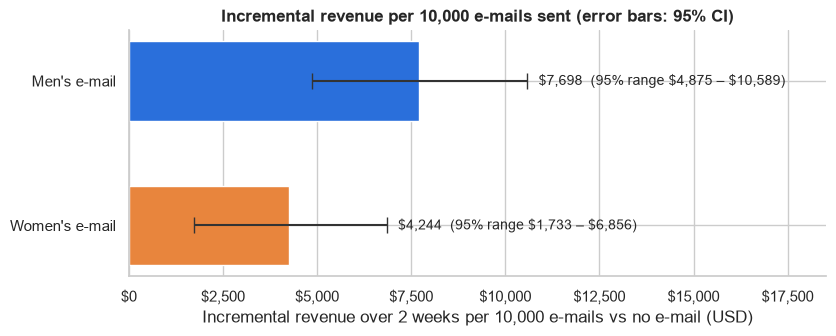

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.2))
y = np.arange(len(CAMPAIGNS))
colors = [ARM_COLORS["Mens E-Mail"], ARM_COLORS["Womens E-Mail"]]
ax.barh(y, revenue.central, color=colors, height=0.55,
        xerr=[revenue.central - revenue.low, revenue.high - revenue.central], capsize=6, ecolor="#333333")
for yi, (c, lo, hi) in enumerate(zip(revenue.central, revenue.low, revenue.high)):
    ax.annotate(f"\\${c:,.0f}  (95% range \\${lo:,.0f} – \\${hi:,.0f})", (hi, yi), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=10)
ax.set_yticks(y, CAMPAIGNS)
ax.invert_yaxis()
ax.set_xlim(0, revenue.high.max() * 1.75)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_xlabel("Incremental revenue over 2 weeks per 10,000 e-mails vs no e-mail (USD)")
ax.set_title("Incremental revenue per 10,000 e-mails sent (error bars: 95% CI)")
fig.savefig(FIG_DIR / "02_incremental_revenue_per_10k.png")
plt.show()

### Sensitivity to e-mail cost

Net contribution per 10,000 e-mails at the assumed 40% margin, for e-mail costs from \$0.01 to \$0.10. Each cell
shows the central estimate and, in brackets, the 95% range. A negative value means the campaign loses money at that
cost.

In [13]:
sens_rows, sens_numeric = [], []
for cost in COSTS:
    row = {"Cost per e-mail": f"${cost:.3f}".rstrip("0").rstrip(".") if cost < 0.1 else f"${cost:.2f}",
           "Cost per 10,000 e-mails": usd(cost * PER)}
    for camp in CAMPAIGNS:
        net = MARGIN * revenue.loc[camp] - cost * PER
        row[camp] = f"{usd(net.central)} [{usd(net.low)} – {usd(net.high)}]"
        sens_numeric.append({"cost_per_email": cost, "campaign": camp, "net_central": net.central,
                             "net_low": net.low, "net_high": net.high})
    sens_rows.append(row)
sensitivity = pd.DataFrame(sens_rows).set_index("Cost per e-mail")
sensitivity.columns.name = f"Net contribution per 10,000 e-mails ({MARGIN:.0%} margin)"
sensitivity

"Net contribution per 10,000 e-mails (40% margin)","Cost per 10,000 e-mails",Men's e-mail,Women's e-mail
Cost per e-mail,,,
$0.01,$100,"$2,979 [$1,850 – $4,136]","$1,598 [$593 – $2,642]"
$0.02,$200,"$2,879 [$1,750 – $4,036]","$1,498 [$493 – $2,542]"
$0.03,$300,"$2,779 [$1,650 – $3,936]","$1,398 [$393 – $2,442]"
$0.05,$500,"$2,579 [$1,450 – $3,736]","$1,198 [$193 – $2,242]"
$0.075,$750,"$2,329 [$1,200 – $3,486]","$948 [−$57 – $1,992]"
$0.10,"$1,000","$2,079 [$950 – $3,236]","$698 [−$307 – $1,742]"


### Break-even cost per e-mail

A campaign breaks even when the cost of an e-mail equals the gross profit it generates:
**break-even cost = margin × incremental revenue per e-mail.** If an e-mail costs less than this, sending it pays.
- The **central** row uses the best estimate of the revenue effect.
- The **conservative** row uses the bottom of its 95% range. This is the cost below which the campaign pays even
  if the true effect is at the low end of what the data allows.

In [14]:
be_rows = []
for camp in CAMPAIGNS:
    for case, col in [("central", "central"), ("conservative (low end of 95% CI)", "low")]:
        row = {"Campaign": camp, "Estimate": case}
        for m in BE_MARGINS:
            label = "Revenue only" if m == 1 else f"{m:.0%} margin"
            row[label] = m * revenue.loc[camp, col] / PER
        be_rows.append(row)
breakeven = pd.DataFrame(be_rows).set_index(["Campaign", "Estimate"])
breakeven.columns.name = "Break-even cost per e-mail (USD)"
breakeven.style.format("${:.3f}")

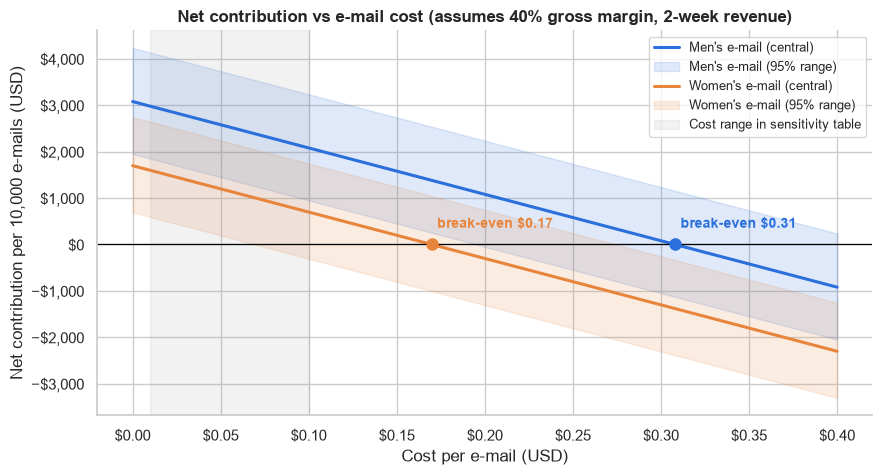

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
cost_grid = np.linspace(0, 0.40, 200)
for camp, color in zip(CAMPAIGNS, colors):
    c, lo, hi = (MARGIN * revenue.loc[camp, k] for k in ["central", "low", "high"])
    ax.plot(cost_grid, c - cost_grid * PER, color=color, lw=2.2, label=f"{camp} (central)")
    ax.fill_between(cost_grid, lo - cost_grid * PER, hi - cost_grid * PER, color=color, alpha=0.15,
                    label=f"{camp} (95% range)")
    be = c / PER
    ax.plot(be, 0, "o", color=color, ms=8, zorder=4)
    ax.annotate(f"break-even \\${be:.2f}", (be, 0), xytext=(4, 12), textcoords="offset points", color=color,
                fontsize=10, fontweight="bold")
ax.axvspan(0.01, 0.10, color="#999999", alpha=0.12, label="Cost range in sensitivity table")
ax.axhline(0, color="black", lw=0.9)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:.2f}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"−${abs(v):,.0f}" if v < 0 else f"${v:,.0f}"))
ax.set_xlabel("Cost per e-mail (USD)")
ax.set_ylabel("Net contribution per 10,000 e-mails (USD)")
ax.set_title(f"Net contribution vs e-mail cost (assumes {MARGIN:.0%} gross margin, 2-week revenue)")
ax.legend(fontsize=9, loc="upper right")
fig.savefig(FIG_DIR / "02_cost_sensitivity.png")
plt.show()

**Reading the results (at the assumed 40% margin):**
- **The men's e-mail pays across the whole \$0.01–\$0.10 cost range, even in the pessimistic case.** Net
  contribution is \$2,079–\$2,979 per 10,000 e-mails, and it stays positive at the low end of the confidence interval
  (\$950 at \$0.10 per e-mail). It breaks even at **\$0.31 per e-mail**, or \$0.19 on the conservative estimate.
- **The women's e-mail pays on its central estimate,** \$698–\$1,598 per 10,000, with break-even at **\$0.17**. Its
  conservative break-even is only **\$0.07**, though: at e-mail costs of about \$0.075 and above, the low end of its
  range turns negative, so profit is not assured.
- **Cost doesn't change which campaign to choose.** Both e-mails cost the same to send, so the men's e-mail earns
  about \$1,380 more net contribution per 10,000 e-mails at *any* cost per e-mail.
- **For context:** bulk e-mail sending usually costs well under \$0.01 per message. The upper part of this table
  matters only if creative production, discounts or other per-send costs are added in.

### Saving the tables

The tables are written to `reports/` so they can be used outside the notebook:
- **`business_impact.md`** is a short, readable version for stakeholders.
- **`business_impact_sensitivity.csv`** holds the full sensitivity numbers for anyone who wants to re-plot them or
  plug in their own margin.

In [16]:
def md_table(frame, index_label):
    esc = lambda x: str(x).replace("$", "\\$")  # GitHub renders $...$ as math unless escaped
    header = [index_label, *frame.columns]
    lines = ["| " + " | ".join(map(esc, header)) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(map(esc, [i, *row])) + " |" for i, row in zip(frame.index, frame.to_numpy())]
    return "\n".join(lines)

be_central = breakeven.xs("central", level="Estimate")
be_low = breakeven.xs("conservative (low end of 95% CI)", level="Estimate")
be_md = pd.DataFrame({col: [f"${c:.2f} (${l:.2f})" for c, l in zip(be_central[col], be_low[col])]
                      for col in breakeven.columns}, index=CAMPAIGNS)

report = f'''# Business impact of the e-mail campaigns

*Source: `notebooks/02_ab_test.ipynb`, section 8. Hillstrom e-mail experiment (2008, USD), revenue over the 2 weeks
after sending. Ranges are 95% confidence intervals.*

## Incremental revenue per 10,000 e-mails (vs no e-mail)

{md_table(revenue_table, "Campaign")}

## Net contribution per 10,000 e-mails by e-mail cost

Assumes a **{MARGIN:.0%} gross margin** (no margin data in the dataset). Net contribution = margin × incremental
revenue − e-mail cost.

{md_table(sensitivity, "Cost per e-mail")}

## Break-even cost per e-mail

Central estimate (conservative estimate, using the low end of the 95% CI). Sending pays while an e-mail costs less
than this.

{md_table(be_md, "Campaign")}

![Incremental revenue](../figures/02_incremental_revenue_per_10k.png)

![Cost sensitivity](../figures/02_cost_sensitivity.png)
'''
(REPORTS_DIR / "business_impact.md").write_text(report, encoding="utf-8")
pd.DataFrame(sens_numeric).to_csv(REPORTS_DIR / "business_impact_sensitivity.csv", index=False)
print("saved reports/business_impact.md and reports/business_impact_sensitivity.csv")

saved reports/business_impact.md and reports/business_impact_sensitivity.csv


## 9. Summary

**1. Both e-mails work.** Each one significantly raised visits, purchases and spend versus sending nothing. All 9
comparisons remain significant after the Holm correction.

**2. The men's e-mail is the stronger campaign.**

| Per 1,000 e-mails sent | Men's e-mail | Women's e-mail |
|---|---|---|
| Extra website visits | **+77** (70 – 83) | +45 (39 – 52) |
| Extra buyers | **+6.8** (5.0 – 8.6) | +3.1 (1.5 – 4.7) |
| Extra revenue (2 weeks) | **+\$770** (\$487 – \$1,059) | +\$424 (\$173 – \$686) |

Head to head, the men's e-mail beats the women's e-mail by 3.1 pp in visits and 0.37 pp in conversion
(both p < 0.001). It also earns \$0.35 more per customer (95% CI \$0.03 – \$0.65, p = 0.03). That revenue edge is
real but less certain than the gains in visits and buyers.

**3. Its extra revenue comes from more buyers, not bigger orders.** The men's e-mail more than doubled the
conversion rate (+119%), but its typical order was smaller: median \$67 vs \$88 for control, with 40% of orders
under \$50. This is descriptive only, since buyers are not a randomized group. Still, it fits a campaign that
brings in additional, smaller purchases.

**4. Method checks.**
- Bootstrap and Welch intervals for spend agree, so the skew in spend does not distort the results.
- Regression adjustment (CUPED-style) left the estimates unchanged, which is consistent with good randomization.
  It added no precision because the dataset has no pre-period measure of spend.

**5. Business impact (section 8).** Per 10,000 e-mails, the men's e-mail brings **+\$7,698** in 2-week revenue
(95% range \$4,875 – \$10,589) and the women's e-mail +\$4,244 (\$1,733 – \$6,856). At an assumed 40% margin:
- **Break-even cost per e-mail:** \$0.31 for the men's e-mail (conservative \$0.19) and \$0.17 for the women's
  (conservative \$0.07).
- **At e-mail costs of \$0.01–\$0.10:**
  - the men's e-mail stays profitable even at the low end of its range;
  - the women's e-mail's low end turns negative from about \$0.075 per e-mail.

**Answer so far:** if the retailer must send **one e-mail to everyone, send the men's e-mail**. That answer covers
only the *average* customer. The open question for **notebook 03** is whether the women's e-mail works better for
some segments, such as customers who previously bought women's merchandise. If so, a targeted strategy could beat
either single campaign. The detectable-effect analysis (section 7) shows that segment comparisons should focus on
visits and conversions, where we have enough data to see differences.

**Outputs:**
- Charts: `figures/02_effects_forest.png`, `figures/02_outcomes_by_group.png`,
  `figures/02_incremental_revenue_per_10k.png`, `figures/02_cost_sensitivity.png`.
- Tables: `reports/business_impact.md`, `reports/business_impact_sensitivity.csv`.